### Claude explanation (not from the professor)
Selects **JAX** as the Keras backend. This must be set before `import keras`. TensorFlow is used only for `tf.data`.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"

import keras
import tensorflow as tf
import sqlite3
import pandas as pd

# Datos

### Claude explanation (not from the professor)
Loads each rating together with **side features**: the book's author, genre, publisher and year, plus the reader's gender and year of birth, joined from `libros` and `lectores`. Ratings whose reader isn't in `lectores` are dropped by the `JOIN`.

In [ ]:
conn = sqlite3.connect('datos/datos.db')

df_ratings = pd.read_sql("""SELECT
    l.id_libro,
    l.autor,
    l.genero,
    l.editorial,
    l.anio_edicion,
    u.id_lector,
    u.genero AS genero_lector,
    u.nacimiento AS anio_nacimiento,
    i.rating
    FROM interacciones AS i
        JOIN libros as l ON l.id_libro = i.id_libro
        JOIN lectores as u ON u.id_lector = i.id_lector
""", conn)

df_ratings.head()

,id_libro,autor,genero,editorial,anio_edicion,id_lector,genero_lector,anio_nacimiento,rating
0,las-puertas-de-anubis,"POWERS, TIM","Fantástica, ciencia ficción",GIGAMESH,2015,bioaqua,Hombre,1976,4
1,antonio-b-el-ruso-ciudadano-de-tercera,"PINILLA, RAMIRO",No Ficción,TUSQUETS,2007,bioaqua,Hombre,1976,10
2,la-momia,"RICE, ANNE",Histórica y aventuras,BYBLOS,2005,bioaqua,Hombre,1976,10
3,el-clan-del-oso-cavernario-los-hijos-de-la-tie...,"AUEL, JEAN MARIE",Histórica y aventuras,MAEVA,2024,bioaqua,Hombre,1976,10
4,dime-quien-soy-1,"NAVARRO, JULIA",Narrativa,PLAZA & JANÉS,2010,bioaqua,Hombre,1976,10


### Claude explanation (not from the professor)
Feature preprocessing:
- Reader, book, publisher, author, genre and reader gender → integer codes for the embeddings. Missing values get code `-1` from `cat.codes`, which isn't a valid embedding index.
- Publication year and birth year → numbers, with missing values set to 0, then min-max scaled to 0–1.
- Rating rescaled from 1–10 to 0–1.

**Note:** filling missing years with 0 before scaling makes 0 the minimum, which squeezes all real years close to 1.

In [ ]:
## user_id
unique_user_id = df_ratings["id_lector"].unique().tolist()
user_id_2_id_mapping = {t:i for i, t in enumerate(unique_user_id)}
id_2_user_id_mapping = {user_id_2_id_mapping[k]: k for k in user_id_2_id_mapping}
df_ratings["id_lector"] = df_ratings["id_lector"].apply(lambda x: user_id_2_id_mapping[x])

## item_id
unique_item_id = df_ratings["id_libro"].unique().tolist()
item_id_2_id_mapping = {t: i for i, t in enumerate(unique_item_id)}
id_2_item_id_mapping = {item_id_2_id_mapping[k]: k for k in item_id_2_id_mapping}
df_ratings["id_libro"] = df_ratings["id_libro"].apply(lambda x: item_id_2_id_mapping[x])

## editorial
df_ratings["editorial"] = df_ratings["editorial"].astype('category').cat.codes

## anio_edicion
df_ratings["anio_edicion"] = pd.to_numeric(df_ratings["anio_edicion"], errors='coerce')
df_ratings["anio_edicion"] = df_ratings["anio_edicion"].fillna(0.0)
df_ratings["anio_edicion"] = (df_ratings["anio_edicion"] - df_ratings["anio_edicion"].min()) / (df_ratings["anio_edicion"].max() - df_ratings["anio_edicion"].min())

## autor
df_ratings["autor"] = df_ratings["autor"].astype('category').cat.codes

## genero
df_ratings["genero"] = df_ratings["genero"].astype('category').cat.codes

## genero_lector
df_ratings["genero_lector"] = df_ratings["genero_lector"].astype('category').cat.codes

# anio_nacimiento
df_ratings["anio_nacimiento"] = pd.to_numeric(df_ratings["anio_nacimiento"], errors='coerce')
df_ratings["anio_nacimiento"] = df_ratings["anio_nacimiento"].fillna(0.0)
df_ratings["anio_nacimiento"] = (df_ratings["anio_nacimiento"] - df_ratings["anio_nacimiento"].min()) / (df_ratings["anio_nacimiento"].max() - df_ratings["anio_nacimiento"].min())

# ratings
df_ratings["rating"] = (df_ratings["rating"] - 1.0) / 9.0

df_ratings.head()

,id_libro,autor,genero,editorial,anio_edicion,id_lector,genero_lector,anio_nacimiento,rating
0,0,15126,20,1164,0.995062,0,1,0.981619,0.333333
1,1,14907,48,2595,0.991111,0,1,0.981619,1.000000
2,2,15861,32,412,0.990123,0,1,0.981619,1.000000
3,3,1090,32,1711,0.999506,0,1,0.981619,1.000000
4,4,13569,46,2141,0.992593,0,1,0.981619,1.000000


### Claude explanation (not from the professor)
Builds the dataset with one named input per feature; the names match the `Input` layers of the model. Same rescaled target, 80/20 split and batching as in the other notebooks.

**Note:** `skip(df_ratings.shape[0] - cut)` skips only 20% of the rows, so the test set is the *last 80%* and mostly overlaps training. It should be `skip(cut)`.

In [ ]:
dataset_inputs = {
    "user_id": df_ratings["id_lector"].to_numpy(dtype="float32"),
    "item_id": df_ratings["id_libro"].to_numpy(dtype="float32"),
    ##
    "editorial_id": df_ratings["editorial"].to_numpy(dtype="float32"),
    "autor_id": df_ratings["autor"].to_numpy(dtype="float32"),
    "genero_id": df_ratings["genero"].to_numpy(dtype="float32"),
    "anio_edicion": df_ratings["anio_edicion"].to_numpy(dtype="float32"),
    "genero_lector_id": df_ratings["genero_lector"].to_numpy(dtype="float32"),
    "anio_nacimiento": df_ratings["anio_nacimiento"].to_numpy(dtype="float32"),
}

dataset_outputs = df_ratings['rating']

dataset = tf.data.Dataset.from_tensor_slices((dataset_inputs, dataset_outputs))
dataset = dataset.shuffle(100_000, seed=42, reshuffle_each_iteration=False)

cut = int(df_ratings.shape[0] * 0.8)
train_dataset = dataset.take(cut).batch(1024).cache()
test_dataset = dataset.skip(df_ratings.shape[0] - cut).batch(1024).cache()

## Una torre (versión funcional)

### Claude explanation (not from the professor)
**One-tower model**, in the Keras functional API. Each categorical feature gets an `Input` and its own `Embedding` (size `min(n//2+1, 50)`), flattened to a vector. The two years go in as plain numbers. Everything is concatenated into one vector and passed through dense layers to a single sigmoid output.

Because reader and book features are mixed from the first layer, the model can learn interactions between them. The trade-off is that it can't precompute book vectors for fast retrieval, as the two-tower model does.

In [ ]:

# usuarios
num_users = df_ratings["id_lector"].nunique() + 1
user_input = keras.layers.Input(shape=[1], name="user_id")
user_embedding = keras.layers.Embedding(num_users, min(num_users//2+1, 50))(user_input)
user_vec = keras.layers.Flatten()(user_embedding)

# items
num_items = df_ratings["id_libro"].nunique() + 1
item_input = keras.layers.Input(shape=[1], name="item_id")
item_embedding = keras.layers.Embedding(num_items, min(num_items//2+1, 50))(item_input)
item_vec = keras.layers.Flatten()(item_embedding)

# editorial
num_editoriales = df_ratings["editorial"].nunique() + 1
editorial_input = keras.layers.Input(shape=[1], name="editorial_id")
editorial_embedding = keras.layers.Embedding(num_editoriales, min(num_editoriales//2+1, 50))(editorial_input)
editorial_vec = keras.layers.Flatten()(editorial_embedding)

# autores
num_autores = df_ratings["autor"].nunique() + 1
autor_input = keras.layers.Input(shape=[1], name="autor_id")
autor_embedding = keras.layers.Embedding(num_autores, min(num_autores//2+1, 50))(autor_input)
autor_vec = keras.layers.Flatten()(autor_embedding)

# genero
num_generos = df_ratings["genero"].nunique() + 1
genero_input = keras.layers.Input(shape=[1], name="genero_id")
genero_embedding = keras.layers.Embedding(num_generos, min(num_generos//2+1, 50))(genero_input)
genero_vec = keras.layers.Flatten()(genero_embedding)

# genero lector
num_genero_lectores = df_ratings["genero_lector"].nunique() + 1
genero_lector_input = keras.layers.Input(shape=[1], name="genero_lector_id")
genero_lector_embedding = keras.layers.Embedding(num_genero_lectores, min(num_genero_lectores//2+1, 50))(genero_lector_input)
genero_lector_vec = keras.layers.Flatten()(genero_lector_embedding)

# anio_edicion
anio_edicion_input = keras.layers.Input(shape=[1], name="anio_edicion")

# anio_nacimiento
anio_nacimiento_input = keras.layers.Input(shape=[1], name="anio_nacimiento")

conc = keras.layers.Concatenate()([user_vec, item_vec, editorial_vec, autor_vec, genero_vec, genero_lector_vec, anio_edicion_input, anio_nacimiento_input])

ratings = keras.Sequential([
    keras.layers.Dense(256, activation="relu"),
    keras.layers.Dense(64, activation="relu"),

    keras.layers.Dense(1, activation='sigmoid'), ## linear
])(conc)

### Claude explanation (not from the professor)
Builds the model from its inputs and output, compiles it (MSE loss, RMSE metric, Adagrad) and draws the architecture. `plot_model` needs `pydot` and Graphviz, and saves the diagram as `model.png`.

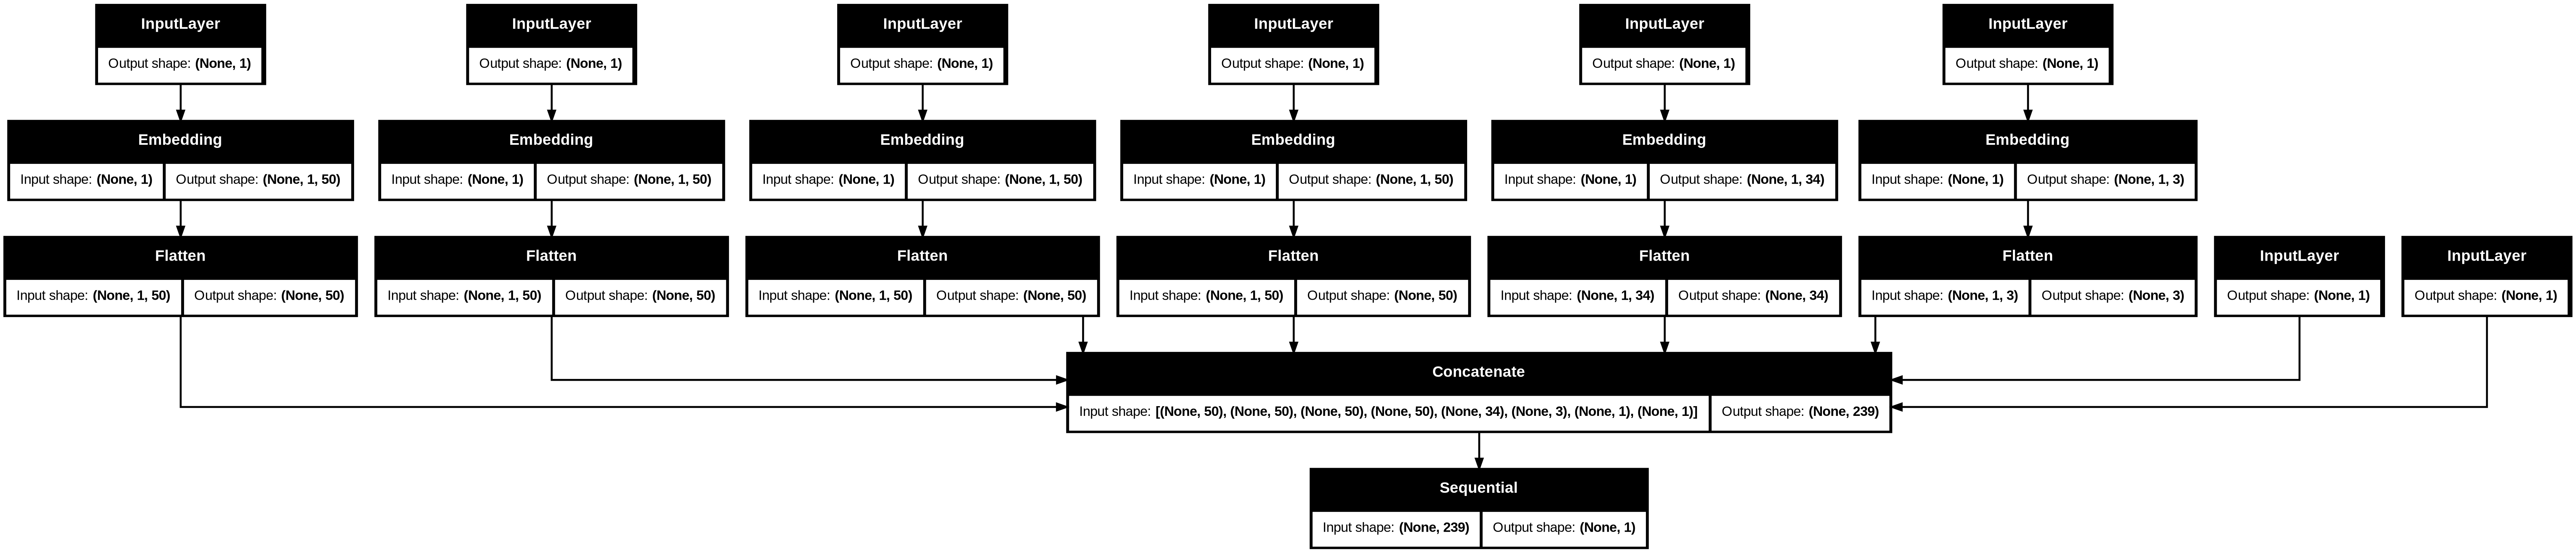

In [ ]:
model = keras.Model(inputs=[user_input, item_input, editorial_input, autor_input, genero_input, anio_edicion_input, anio_nacimiento_input, genero_lector_input], outputs=ratings)

model.compile(
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.RootMeanSquaredError()],
    optimizer=keras.optimizers.Adagrad(learning_rate=0.1)
)

from keras.utils import plot_model
plot_model(model, show_shapes=True)


### Claude explanation (not from the professor)
Trains for up to 100 epochs with two callbacks:
- `EarlyStopping` stops after 3 epochs without improvement in `loss`.
- `ModelCheckpoint` saves the model to `checkpoint.keras` whenever validation RMSE improves.

**Note:** `EarlyStopping` watches the *training* loss, which nearly always keeps falling; `val_loss` would catch overfitting. With `validation_freq=5`, validation RMSE only exists every 5th epoch, so the checkpoint can only save on those epochs.

In [ ]:
# Detiene el entrenamiento cuando no hay mejora en loss en tres épocas consecutivas
es_callback = keras.callbacks.EarlyStopping(monitor='loss', patience=3)

# Graba el modelo cuando cambia val_root_mean_squared_error
#mc_callback = keras.callbacks.ModelCheckpoint(filepath="checkpoint.{val_root_mean_squared_error:.2f}.weights.h5", monitor="val_root_mean_squared_error", mode="min",  save_weights_only=True, save_best_only=True)
mc_callback = keras.callbacks.ModelCheckpoint(filepath="checkpoint.keras", monitor="val_root_mean_squared_error", mode="min",  save_weights_only=False, save_best_only=True)

history = model.fit(train_dataset,
                    validation_data=test_dataset,
                    validation_freq=5,
                    epochs=100,
                    batch_size=1024,
                    callbacks=[es_callback, mc_callback]
                    )

Epoch 1/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0394 - root_mean_squared_error: 0.1986
Epoch 2/100
  1/361 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0376 - root_mean_squared_error: 0.1938

/usr/local/lib/python3.13/dist-packages/keras/src/callbacks/model_checkpoint.py:276: UserWarning: Can save best model only with val_root_mean_squared_error available.
  if self._should_save_model(epoch, batch, logs, filepath):


361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0390 - root_mean_squared_error: 0.1975
Epoch 3/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0386 - root_mean_squared_error: 0.1966
Epoch 4/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0383 - root_mean_squared_error: 0.1957
Epoch 5/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 0.0380 - root_mean_squared_error: 0.1949 - val_loss: 0.0394 - val_root_mean_squared_error: 0.1985
Epoch 6/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0376 - root_mean_squared_error: 0.1938
Epoch 7/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0370 - root_mean_squared_error: 0.1925
Epoch 8/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0364 - root_mean_squared_error: 0.1909
Epoch 9/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0357 - root_mean_squared_error: 0.1890
Epoch 10/100
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0350 - root_mean_squared_error: 0.1872 - val_loss: 0.0365 - val_root_mean_